# Step 11: Leakage check, random split vs time-aware split

**Question:** how much does a random train/test split overstate accuracy compared with testing on later batches?

We give the **same seven models with the same settings** (library defaults, scaler, no PCA/LDA; Steps 5 and 7) three
different exams:

| Exam | Training rows | Test rows | Time order respected? |
|---|---|---|---|
| **Time-aware (protocol A)** | batches 1-3 (3,196 rows) | batches 4-10 (8,881 rows) | yes |
| **Random 80/20** | 80% of all rows (9,661) | 20% of all rows (2,416) | no |
| **Random, same sizes as protocol A** | 3,196 random rows | the other 8,881 rows | no |

The third exam is a **fair control**: it has exactly the same amount of training and test data as protocol A,
so the only thing that differs is whether time was respected. Random splits are repeated for 3 seeds (0, 1, 2) and
averaged. The time-aware numbers come from Steps 5 and 7 (identical models, nothing re-tuned).

In [1]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from src import data_loader as dl
from src import leakage

pd.set_option("display.width", 170)

def read(name):
    # keep_default_na=False: otherwise pandas turns the text "None" (no reduction) into a missing value
    return pd.read_csv(f"../results/{name}", keep_default_na=False)

rand = pd.read_csv("../results/step11_random_vs_time_aware.csv")
MODELS = ["kNN", "SVM", "Decision Tree", "Random Forest", "Naive Bayes", "AdaBoost", "Gradient Boosting"]
SCHEMES = ["random 80/20", "random, same sizes as protocol A"]
assert set(rand["model"]) == set(MODELS) and set(rand["scheme"]) == set(SCHEMES) and rand["seed"].nunique() == 3, "results incomplete"
print("rows:", len(rand), "(7 models x 2 exams x 3 seeds)")

# time-aware results (protocol A) from Step 5 (baselines) and Step 7 (boosting, no reduction)
s5 = read("step5_baseline_metrics.csv")
s7 = read("step7_boosting_metrics.csv"); s7 = s7[s7["reduction"] == "None"]
time_aware = pd.concat([s5, s7], ignore_index=True)
time_aware = time_aware[time_aware["protocol"] == "A"]
ta_pooled = time_aware[time_aware["test_batch"] == "pooled"].set_index("model").loc[MODELS]
ta_batch = time_aware[time_aware["test_batch"] != "pooled"].assign(b=lambda d: d["test_batch"].astype(int)).pivot(
    index="model", columns="b", values="accuracy").loc[MODELS]
ta_pooled[["accuracy", "macro_f1"]].round(3)

rows: 42 (7 models x 2 exams x 3 seeds)


,accuracy,macro_f1
model,,
kNN,0.696,0.707
SVM,0.727,0.740
Decision Tree,0.497,0.466
Random Forest,0.647,0.617
Naive Bayes,0.565,0.567
AdaBoost,0.472,0.452
Gradient Boosting,0.558,0.547


## 1. Pooled accuracy under the three exams

In [2]:
g = rand.groupby(["model", "scheme"])["accuracy"].agg(["mean", "std"]).unstack("scheme").loc[MODELS]
table = pd.DataFrame({
    "time-aware (A)": ta_pooled["accuracy"] * 100,
    "random, same sizes": g[("mean", SCHEMES[1])] * 100,
    "random 80/20": g[("mean", SCHEMES[0])] * 100,
})
table["gap: same-size random minus time-aware"] = table["random, same sizes"] - table["time-aware (A)"]
table["gap: random 80/20 minus time-aware"] = table["random 80/20"] - table["time-aware (A)"]
std = pd.DataFrame({"std over seeds (same sizes)": g[("std", SCHEMES[1])] * 100, "std over seeds (80/20)": g[("std", SCHEMES[0])] * 100})
table.round(1).to_csv("../results/step11_accuracy_table.csv")
print("Pooled accuracy (%), mean over 3 random seeds")
table.round(1)

Pooled accuracy (%), mean over 3 random seeds


,time-aware (A),"random, same sizes",random 80/20,gap: same-size random minus time-aware,gap: random 80/20 minus time-aware
model,,,,,
kNN,69.6,98.3,99.3,28.7,29.7
SVM,72.7,97.2,98.4,24.5,25.6
Decision Tree,49.7,95.6,97.9,45.9,48.2
Random Forest,64.7,99.0,99.4,34.2,34.7
Naive Bayes,56.5,64.2,65.8,7.7,9.3
AdaBoost,47.2,85.2,86.6,38.0,39.3
Gradient Boosting,55.8,98.7,99.2,42.9,43.4


In [3]:
print("Largest spread over the 3 random seeds (percentage points):", round(std.max().max(), 2))
macro = rand.groupby(["model", "scheme"])["macro_f1"].mean().unstack("scheme").loc[MODELS] * 100
macro.insert(0, "time-aware (A)", ta_pooled["macro_f1"] * 100)
print("Pooled macro-F1 (%)")
macro.round(1)

Largest spread over the 3 random seeds (percentage points): 2.5
Pooled macro-F1 (%)


scheme,time-aware (A),random 80/20,"random, same sizes as protocol A"
model,,,
kNN,70.7,99.3,98.2
SVM,74.0,98.2,97.0
Decision Tree,46.6,97.7,95.3
Random Forest,61.7,99.4,98.9
Naive Bayes,56.7,66.3,64.7
AdaBoost,45.2,84.9,83.6
Gradient Boosting,54.7,99.2,98.6


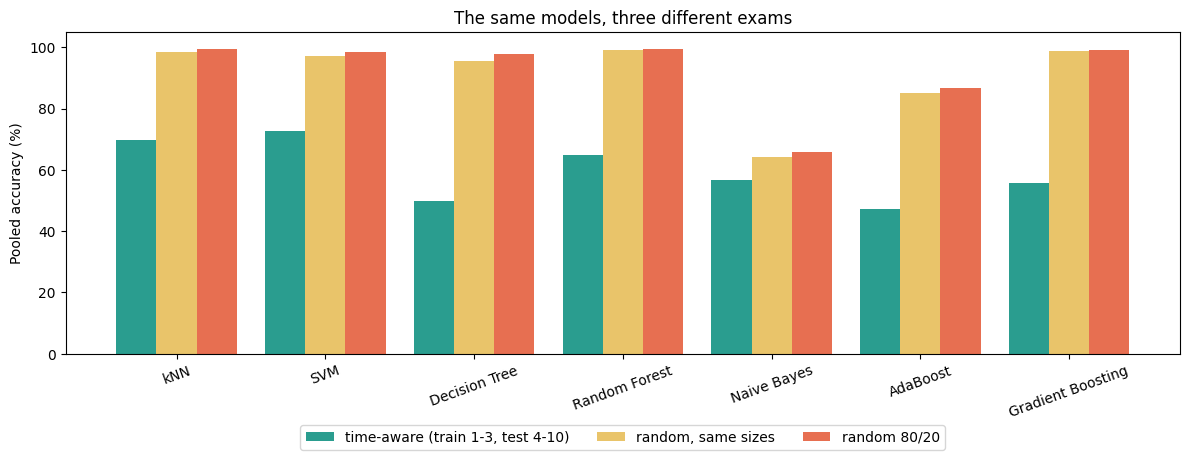

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.8))
x = np.arange(len(MODELS)); w = 0.27
ax.bar(x - w, table["time-aware (A)"], w, label="time-aware (train 1-3, test 4-10)", color="#2a9d8f")
ax.bar(x, table["random, same sizes"], w, label="random, same sizes", color="#e9c46a")
ax.bar(x + w, table["random 80/20"], w, label="random 80/20", color="#e76f51")
ax.set_xticks(x); ax.set_xticklabels(MODELS, rotation=20)
ax.set_ylim(0, 105); ax.set_ylabel("Pooled accuracy (%)")
ax.set_title("The same models, three different exams")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.savefig("../results/step11_random_vs_time_aware.png", dpi=150, bbox_inches="tight")
plt.show()

**What to notice (pooled accuracy; random results are the mean of 3 seeds, which differ by at most 2.5 points):**

| Model | Time-aware | Random, same sizes | Random 80/20 |
|---|---|---|---|
| kNN | 69.6% | 98.3% | 99.3% |
| SVM | 72.7% | 97.2% | 98.4% |
| Decision Tree | 49.7% | 95.6% | 97.9% |
| Random Forest | 64.7% | 99.0% | 99.4% |
| Gradient Boosting | 55.8% | 98.7% | 99.2% |
| AdaBoost | 47.2% | 85.2% | 86.6% |
| Naive Bayes | 56.5% | 64.2% | 65.8% |

- **A random split makes five of the seven models look almost perfect** (96-99%), while the same models score 50-73% when
  tested on later batches. The inflation is 25 to 46 points for those five models (same-size control).
- **The control rules out "more training data" as the reason.** The random split with exactly protocol A's sizes
  (3,196 training rows) is only 0.4 to 2.3 points below the 80/20 split. The big jump comes from ignoring time, not from
  having more data.
- **The model ranking flips.** Under a random 80/20 split the best models are Random Forest (99.4%), kNN (99.3%) and
  Gradient Boosting (99.2%); under the time-aware split the best is SVM (72.7%), and Gradient Boosting falls to 55.8%,
  a drop of 43 points. Choosing a model with a random split would pick the wrong one for a sensor that ages.
- **Naive Bayes** has the smallest gap (7.7 points) but only because it is weak either way (about 65% even in a random
  split). That is not a sign that it handles drift well.

## 2. Per batch: does the drop with time disappear in a random split?

In [5]:
cols = [f"acc_batch{b}" for b in range(1, 11)]
r80 = rand[rand["scheme"] == SCHEMES[0]].groupby("model")[cols].mean().loc[MODELS] * 100
r80.columns = range(1, 11)
print("Random 80/20: accuracy (%) inside each batch's test rows")
r80.round(1)

Random 80/20: accuracy (%) inside each batch's test rows


,1,2,3,4,5,6,7,8,9,10
model,,,,,,,,,,
kNN,97.6,98.8,99.3,93.3,98.4,99.2,100.0,100.0,98.7,99.5
SVM,89.1,97.5,99.3,100.0,99.3,99.6,99.6,95.7,96.5,97.5
Decision Tree,91.7,98.0,99.5,96.3,95.3,98.6,99.2,93.7,98.7,96.5
Random Forest,98.0,99.1,99.9,100.0,99.3,99.4,99.8,97.5,100.0,99.2
Naive Bayes,54.8,64.8,81.3,70.7,71.2,65.9,71.8,25.0,45.1,59.0
AdaBoost,67.9,91.2,93.4,92.0,88.1,96.5,89.0,84.5,89.8,73.9
Gradient Boosting,96.0,98.9,99.8,98.1,100.0,99.1,99.8,98.1,98.2,99.0


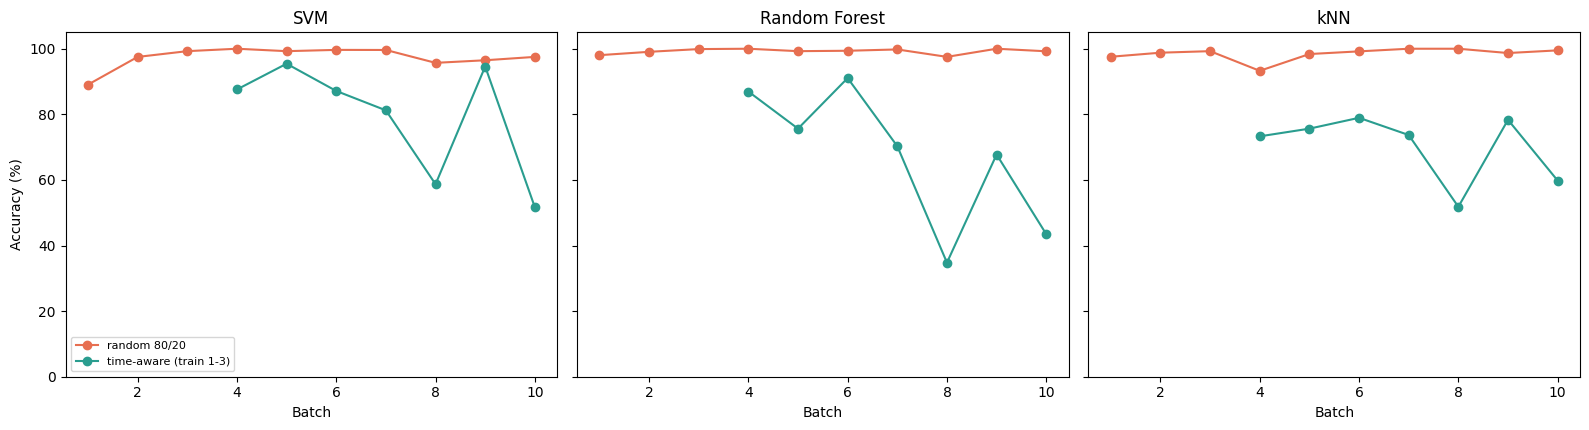

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, m in zip(axes, ["SVM", "Random Forest", "kNN"]):
    ax.plot(range(1, 11), r80.loc[m], marker="o", color="#e76f51", label="random 80/20")
    ax.plot(ta_batch.columns, ta_batch.loc[m] * 100, marker="o", color="#2a9d8f", label="time-aware (train 1-3)")
    ax.set_title(m); ax.set_xlabel("Batch"); ax.set_ylim(0, 105)
axes[0].set_ylabel("Accuracy (%)"); axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("../results/step11_per_batch.png", dpi=150)
plt.show()

**What to notice:** in the random split the accuracy is flat and high in **every** batch, including batch 10
(SVM 97.5%, Random Forest 99.2%, kNN 99.5%). In the time-aware exam the same models fall to 52%, 44% and 60% on batch 10.
In other words, **a random split makes drift invisible**: the batch-to-batch decline we measured in Steps 5 to 10
simply does not show up, which is exactly why it can hide the real problem.

## 3. Why? Test rows in a random split have near-twins in the training set

In [7]:
df = dl.remove_toluene(dl.load_all())
Z = StandardScaler().fit_transform(df[dl.FEATURE_COLS].to_numpy())   # descriptive diagnostic only
batch = df["batch"].to_numpy()

def nearest_info(tr, te):
    nn = NearestNeighbors(n_neighbors=1).fit(Z[tr])
    dist, idx = nn.kneighbors(Z[te])
    return dist[:, 0], batch[tr][idx[:, 0]]

rows = []
tr, te = leakage.random_split(df, 0)
d, nb_ = nearest_info(tr, te)
rows.append({"exam": "random 80/20", "median distance to nearest training row": np.median(d),
             "test rows whose nearest training row is from the same batch (%)": (nb_ == batch[te]).mean() * 100})
tr, te = leakage.size_matched_split(df, 0, 3196)
d, nb_ = nearest_info(tr, te)
rows.append({"exam": "random, same sizes as protocol A", "median distance to nearest training row": np.median(d),
             "test rows whose nearest training row is from the same batch (%)": (nb_ == batch[te]).mean() * 100})
tr = np.where(batch <= 3)[0]; te = np.where(batch >= 4)[0]
d, nb_ = nearest_info(tr, te)
rows.append({"exam": "time-aware (protocol A)", "median distance to nearest training row": np.median(d),
             "test rows whose nearest training row is from the same batch (%)": 0.0})
nn_table = pd.DataFrame(rows).set_index("exam")
nn_table.round(2).to_csv("../results/step11_nearest_neighbour.csv")
nn_table.round(2)

,median distance to nearest training row,test rows whose nearest training row is from the same batch (%)
exam,,
random 80/20,0.43,98.68
"random, same sizes as protocol A",0.51,97.71
time-aware (protocol A),3.03,0.00


**What to notice:**

| Exam | Median distance from a test row to its nearest training row | Nearest training row is from the same batch |
|---|---|---|
| Random 80/20 | 0.43 | 98.7% |
| Random, same sizes | 0.51 | 97.7% |
| Time-aware (protocol A) | 3.03 | 0% (impossible by design) |

- **In a random split, almost every test row has a near-twin in the training set**, taken from the same batch (the same
  recording session). A model can score highly just by recognising that twin, without learning anything that would still
  work after the sensor has changed.
- **In the time-aware exam the nearest training row is about 6 to 7 times further away.** The model has to generalise
  across the drift, which is the real task.
- This agrees with Step 3, where a Random Forest could tell which batch a sample came from with about 99% accuracy.
- Caveat: the distance is measured in a scaled 128-dimensional space, with a scaler fitted on all rows. It is a
  descriptive diagnostic only and no model used it.

## Summary of Step 11
- **A random split overstates accuracy massively:** five of the seven models reach 96-99% (same-size control and 80/20)
  against 50-73% under the time-aware split, an inflation of 25-46 points.
- **It is not caused by having more training data** (the same-size random control is within 0.4-2.3 points of the 80/20 split).
  It is caused by near-twin rows from the same batch appearing in both training and test sets (98% of test rows have
  their nearest training row in the same batch).
- **A random split hides drift** (flat 90-100% in every batch) **and picks the wrong model** (Gradient Boosting looks like 99%
  but is 55.8% under drift, while SVM is 72.7%).
- This is the evidence for the research gap in your slides: random splitting risks misleading results (Dennler et al. 2022).
- Limits: 3 random seeds, default settings without reduction, one time-aware training split (batches 1-3), and the
  distance diagnostic is descriptive. We show *that* leakage happens, not exactly *which* sample properties cause it.